# Baseline runner: teach Qwen and SmolVLM to name OSMa regions

This first experiment adapts **Qwen3-VL-2B-Instruct** and **SmolVLM2-2.2B-Instruct** to OSMa's category vocabulary using separate LoRA adapters. It measures **GT-assisted region classification**. It is an object-naming component experiment; it does not yet build or evaluate a complete scene graph.

**Run All initially prepares local examples and previews only.** Model loading, package installation, training, adapter reload, and final test evaluation are off by default. Download data and the selected model using `../download_dependencies.ipynb` first; this notebook loads models locally and never fetches weights.

The reusable implementation is in `lora_baseline.py`, alongside this notebook. The comments below explain the data flow and the controls you change. Start with the small pilot; 20 optimizer steps check the pipeline and are not a converged experiment.

In [1]:
# Find the project from either the repository root or this notebook's directory.
from pathlib import Path
import sys, json, importlib.metadata, importlib.util, copy

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "code" / "download_dependencies.ipynb").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside the Senior Capstone repository.")
sys.path.insert(0, str(ROOT / "code" / "midterm_report"))
import lora_baseline as lb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_ROOT = ROOT / "dataset" / "osma-bench" / "data"
print("Project:", ROOT)
print("Python:", sys.executable)
for package in ("torch", "transformers", "peft", "accelerate", "bitsandbytes", "num2words"):
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, "not installed (needed only for the training cells)")

Project: d:\School Stuff\shanghai work\Senior Capstone
Python: c:\ProgramData\anaconda3\envs\cleanjupyter\python.exe
torch 2.14.1+cu126
transformers 5.19.0
peft 0.21.2
accelerate 1.15.0
bitsandbytes 0.50.2
num2words 0.5.14


## 1. What becomes a training example?

| OSMa file | Use in this pilot |
|---|---|
| `results/frameXXXXXX.jpg` | The actual RGB pixels supplied to the VLM. |
| `results/semanticXXXXXX.png` | Class IDs used to propose connected regions and crop boxes. Never included in the model prompt. |
| `embed_semseg_classes.json` | Converts a region's class ID into the target category text, e.g. `chair`. IDs are interpreted per scene. |
| `traj.txt`, depth, intrinsics | Reserved for later 3D projection, fusion and graph construction. They are not object-naming inputs here. |
| VQA / descriptions JSON | Not used as object or relation labels. Question answers do not automatically annotate every visible object or object pair. |

**Flow:** semantic mask → candidate rectangle → crop the RGB image → image + fixed question → predict category name → compare with category target.

A connected semantic region is a **weak proposal**, not a GT object instance: touching chairs may merge, and an occluded chair may split. The crop keeps natural background pixels. This gives a controlled naming experiment with GT-assisted localization; a later experiment must also test detector-generated crops to measure construction failures.

In [2]:
# Shared settings for BOTH models. Changing them produces a new dataset fingerprint.
DATA_SETTINGS = copy.deepcopy(lb.DEFAULT_DATA)
DATA_SETTINGS.update(
    seed=42,
    frames_per_scene=6,                   # Evenly sample a small pilot from each trajectory.
    max_regions_per_frame=4,
    max_examples_per_class_per_scene=4,  # Limit repeated common categories.
    image_max_side=384,                   # Same source crop resolution for both VLMs.
)
# Related ReplicaCAD v3_scN_staging_* scenes share one split automatically.
# This filename heuristic needs review: add known shared layouts here BEFORE training.
# Example: {"replica_cad/scene_a": "layout_A", "replica_cad/scene_b": "layout_A"}
DATA_SETTINGS["group_overrides"] = {}

# CPU-only preparation: reads selected local RGB/semantic files, never loads a VLM.
# Original dataset files are unchanged. Repeating this cell is deterministic.
manifest = lb.prepare_examples(DATA_ROOT, DATA_SETTINGS)
MANIFEST_PATH = ROOT / "dataset" / "_training" / "osma_regions" / manifest["fingerprint"] / "manifest.json"
lb.save_json(MANIFEST_PATH, manifest)
examples = pd.DataFrame(manifest["examples"])
print("Manifest:", MANIFEST_PATH)
print("Dataset fingerprint:", manifest["fingerprint"])
display(examples.groupby("split").agg(examples=("id", "size"), scenes=("scene", "nunique"),
                                     groups=("group", "nunique"), categories=("target", "nunique")))

Prepared hm3d/00800-TEEsavR23oF: 22 region examples (train).
Prepared hm3d/00802-wcojb4TFT35: 22 region examples (train).
Prepared hm3d/00803-k1cupFYWXJ6: 16 region examples (validation).
Prepared hm3d/00808-y9hTuugGdiq: 22 region examples (train).
Prepared hm3d/00810-CrMo8WxCyVb: 24 region examples (validation).
Prepared hm3d/00813-svBbv1Pavdk: 21 region examples (test).
Prepared hm3d/00814-p53SfW6mjZe: 24 region examples (train).
Prepared hm3d/00815-h1zeeAwLh9Z: 24 region examples (test).
Prepared replica_cad/apt_0: 23 region examples (train).
Prepared replica_cad/apt_3: 19 region examples (test).
Prepared replica_cad/v3_sc0_staging_00: 22 region examples (validation).
Prepared replica_cad/v3_sc0_staging_12: 21 region examples (validation).
Prepared replica_cad/v3_sc0_staging_16: 20 region examples (validation).
Prepared replica_cad/v3_sc0_staging_19: 22 region examples (validation).
Prepared replica_cad/v3_sc0_staging_20: 21 region examples (validation).
Prepared replica_cad/v3_sc1_

,examples,scenes,groups,categories
split,,,,
test,64,3,3,37
train,441,20,8,62
validation,146,7,3,36


## 2. Inspect the split and labels before interpreting results

We split **scene/layout groups**, not individual frames. Adjacent frames often show the same objects; randomly splitting frames would inflate performance. HM3D and ReplicaCAD are split separately to include both families. Review the group table and update overrides when two differently named scenes share a layout. Group independence is not guaranteed by filenames alone.

Training uses only `train`; checkpoint selection and pilot scores use `validation`. Keep `test` untouched until the settings are fixed. The category vocabularies may differ between splits; the table below exposes held-out labels absent from training. This is not a benchmark-standard split.

In [3]:
scene_table = pd.DataFrame.from_dict(manifest["scenes"], orient="index").rename_axis("scene").reset_index()
assert scene_table.groupby("group")["split"].nunique().max() == 1
assert set(examples["split"]) == {"train", "validation", "test"}
assert examples["id"].is_unique
display(scene_table.sort_values(["split", "group", "scene"]))
train_labels = set(examples.loc[examples.split == "train", "target"])
for split in ("validation", "test"):
    unseen = sorted(set(examples.loc[examples.split == split, "target"]) - train_labels)
    print(split, "categories absent from training:", unseen)
display(pd.crosstab(examples.target, examples.split).sort_index().head(30))

,scene,group,split
5,hm3d/00813-svBbv1Pavdk,hm3d/00813-svBbv1Pavdk,test
7,hm3d/00815-h1zeeAwLh9Z,hm3d/00815-h1zeeAwLh9Z,test
9,replica_cad/apt_3,replica_cad/apt_3,test
0,hm3d/00800-TEEsavR23oF,hm3d/00800-TEEsavR23oF,train
1,hm3d/00802-wcojb4TFT35,hm3d/00802-wcojb4TFT35,train
3,hm3d/00808-y9hTuugGdiq,hm3d/00808-y9hTuugGdiq,train
6,hm3d/00814-p53SfW6mjZe,hm3d/00814-p53SfW6mjZe,train
8,replica_cad/apt_0,replica_cad/apt_0,train
15,replica_cad/v3_sc1_staging_00,replica_cad/v3_sc1,train
16,replica_cad/v3_sc1_staging_06,replica_cad/v3_sc1,train


validation categories absent from training: ['arcade', 'armchair', 'balustrade', 'bust', 'fireplace', 'framed text', 'seat', 'sensor', 'sign', 'stained glass', 'window frame']
test categories absent from training: ['basket', 'beam', 'bin', 'ceiling lamp', 'decor', 'desk', 'dining chair', 'dishwasher', 'fireplace', 'kitchen countertop item', 'microwave', 'paper towel', 'plant', 'terrace', 'ventilation', 'wall control', 'wall lamp', 'window glass']


split,test,train,validation
target,,,
alarm,0,1,0
arcade,0,0,1
armchair,0,0,3
bag,0,2,0
balustrade,0,0,3
banister,0,1,0
base cabinet,0,16,2
basket,1,0,0
beam,3,0,0


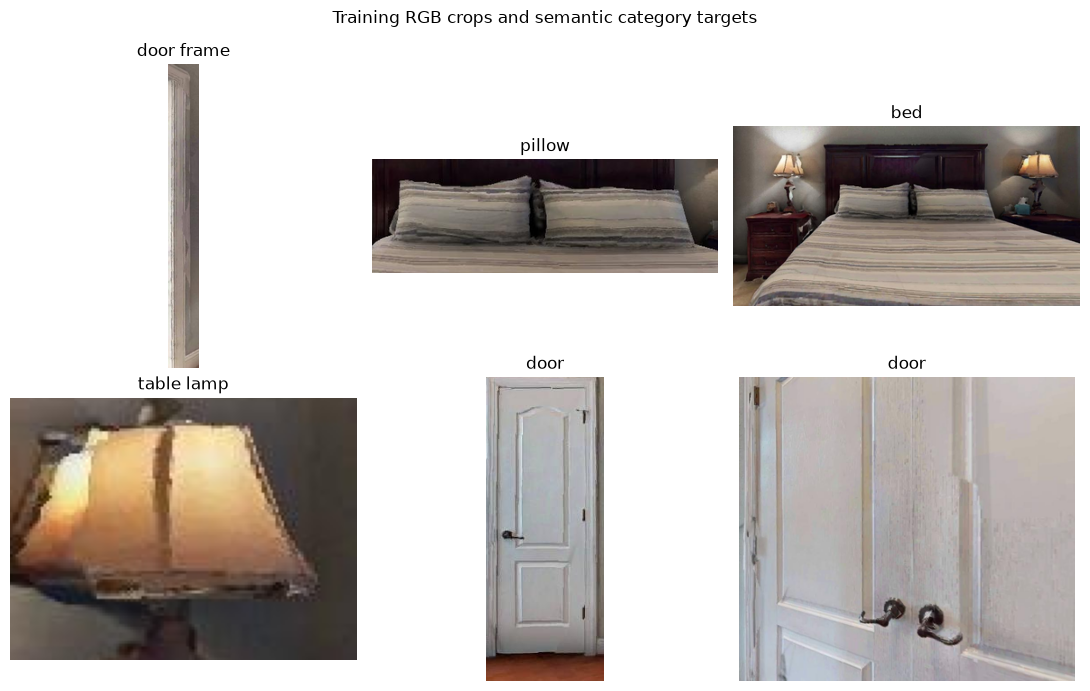

{
  "messages": [
    {
      "role": "user",
      "content": [
        {
          "type": "image",
          "image": "<PIL RGB crop, not its filename>"
        },
        {
          "type": "text",
          "text": "Name the main object or semantic region in this RGB crop. Reply with only a short category name."
        }
      ]
    },
    {
      "role": "assistant",
      "content": [
        {
          "type": "text",
          "text": "door frame"
        }
      ]
    }
  ]
}


In [4]:
# Check that the target category is visibly supported by its crop.
# Targets appear in plot titles for YOU; these titles are never model inputs.
preview_rows = examples.loc[examples.split == "train"].head(6).to_dict("records")
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, row in zip(axes.flat, preview_rows):
    ax.imshow(lb.load_crop(row, DATA_ROOT, DATA_SETTINGS["image_max_side"]))
    ax.set_title(row["target"])
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Training RGB crops and semantic category targets")
plt.tight_layout()
plt.show()

example = preview_rows[0]
print(json.dumps({
    "messages": [
        {"role": "user", "content": [
            {"type": "image", "image": "<PIL RGB crop, not its filename>"},
            {"type": "text", "text": lb.PROMPT}]},
        {"role": "assistant", "content": [{"type": "text", "text": example["target"]}]}
    ]
}, indent=2))

## 3. What LoRA changes

For a frozen decoder weight matrix **W**, LoRA learns two small matrices **A** and **B**:

`adapted output = W @ input + (alpha / rank) * B @ A @ input`

The original pretrained weights remain frozen. `rank=8` is the small adapter dimension; `alpha=16` scales its contribution. `dropout=0.05` regularizes the adapter branch during training. Attaching an adapter only initializes these matrices: it has **not learned OSMa yet**.

We adapt the text decoder's attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`). Qwen uses `model.language_model`; SmolVLM uses `model.text_model`. The helper selects full module paths so similarly named vision layers are excluded. The vision encoder and projector remain frozen. Each architecture gets its **own** adapter; their weights cannot be exchanged.

With `USE_4BIT=True`, this is **QLoRA**: the base uses 4-bit weights while the small adapters remain trainable at higher precision. Start with one model, microbatch 1, accumulation 4 and small crops. This is intended as an 8 GB GPU pilot, but full-size training memory has not been validated on your machine. If it runs out of memory, restart the kernel and reduce `image_max_side` and Qwen's image-token budget in the helper. Accumulation increases effective batch size without increasing the microbatch.

In [5]:
# Optional one-time setup. False means Run All never installs packages.
# Use a CUDA-enabled PyTorch environment with Transformers supporting Qwen3-VL.
# Do not replace your existing PyTorch installation automatically.
INSTALL_TRAINING_PACKAGES = False
if INSTALL_TRAINING_PACKAGES:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "peft>=0.18", "accelerate>=1.0", "bitsandbytes>=0.48", "num2words"])
    # SmolVLM caches optional dependency availability when first imported.
    # Reloading lb alone will not refresh that cache; restart the kernel.
    print("Restart the kernel after installation, then rerun from the top.")
else:
    print("Installation skipped. Preparation does not need PEFT/bitsandbytes.")
# If this Python version has no compatible binary wheels, use a separate
# supported Python/CUDA environment (e.g. Python 3.11/3.12), not an in-place downgrade.

Installation skipped. Preparation does not need PEFT/bitsandbytes.


In [ ]:
# Run Qwen first; restart the kernel, switch to "smolvlm", and repeat with
# the SAME data settings and training budget for a controlled comparison.
MODEL_KEY = "smolvlm"                       # "qwen" or "smolvlm"
USE_4BIT = True
LORA = {"rank": 8, "alpha": 16, "dropout": 0.05}
TRAINING = {
    "max_steps": -1,                     # Positive value overrides epochs; pilot only.
    "epochs": 3,
    "accumulation": 4,                   # Effective batch = 1 x 4 on one GPU.
    "learning_rate": 1e-4,
    "eval_steps": 10,
    "eval_examples": 30,                 # Fixed validation subset for generation scores.
}
RUN_NAME = "objects_3epochs"             # Same name for either model; training alone may add a suffix.
LOAD_MODEL = False                       # Set True to load local weights + fresh LoRA.
RUN_TRAINING = False                     # Set True only when you want optimizer updates.
RELOAD_ADAPTER = True                   # Optional demonstration using a completed run.
RUN_FINAL_TEST = True                   # Leave False while choosing settings.

if MODEL_KEY not in lb.MODELS:
    raise ValueError("MODEL_KEY must be qwen or smolvlm.")
# Saved runs: artifacts/objects/<model>/<run>/; dataset fingerprints stay in metadata.
RUN_DIR = lb.artifact_run_directory(ROOT, "objects", MODEL_KEY, RUN_NAME)
run_signature = lb.fingerprint({"model": MODEL_KEY, "data": manifest["fingerprint"],
                                "lora": LORA, "use_4bit": USE_4BIT})
print("Base model:", lb.MODELS[MODEL_KEY]["repo_id"])
print("Run output:", RUN_DIR)

In [7]:
if LOAD_MODEL:
    # Prevent accidentally keeping two VLMs in the same GPU memory.
    if "model" in globals():
        raise RuntimeError("A model is already loaded. Restart the kernel for a fresh training run.")
    required = ["torch", "transformers", "peft", "accelerate"] + (["bitsandbytes"] if USE_4BIT else [])
    if MODEL_KEY == "smolvlm":
        required.append("num2words")  # SmolVLM's processor requires this even for RGB crops.
    missing = [p for p in required if importlib.util.find_spec(p) is None]
    if missing:
        raise RuntimeError("Install missing training packages first: " + ", ".join(missing))
    model, processor, lora_config, trainable_parameters = lb.load_trainable(
        ROOT, MODEL_KEY, **LORA, use_4bit=USE_4BIT, seed=DATA_SETTINGS["seed"])
    loaded_signature = run_signature
    training_started = False
    print("Only these LoRA matrices are trainable (first eight):")
    display(pd.DataFrame(trainable_parameters, columns=["parameter", "elements"]).head(8))
    print("LoRA configuration:", lora_config)
else:
    print("Model loading skipped. Set LOAD_MODEL=True to inspect fresh LoRA matrices.")

Model loading skipped. Set LOAD_MODEL=True to inspect fresh LoRA matrices.


## 4. How the image and answer enter the loss

The model-specific processor converts RGB pixels into image tensors and formats the conversation using its own chat template. The target category is the **assistant answer** during supervised training. At inference, there is only the user image and question; the correct answer is not supplied.

`input_ids` includes the training conversation. `labels` is a copy with **all user/prompt/image positions set to -100**, which tells the causal language-model loss to ignore those positions. Only the assistant answer and its ending are scored. The model shifts next-token targets internally. No truncation is used because removing image tokens can break alignment. The helper verifies that the inference prompt is an exact prefix of the training conversation and stops if the template differs.

Microbatch size must remain **1** with this teaching collator. Use gradient accumulation to increase effective batch size. Both models see identical source crops and prompts; their processors and image-token layouts naturally differ.

In [8]:
if LOAD_MODEL:
    if loaded_signature != run_signature:
        raise RuntimeError("Configuration changed after model loading; restart and reload.")
    training_example = next(r for r in manifest["examples"] if r["split"] == "train")
    batch = lb.RegionCollator(processor, DATA_ROOT, DATA_SETTINGS["image_max_side"])([training_example])
    print("Processor tensors:", {k: tuple(v.shape) for k, v in batch.items() if hasattr(v, "shape")})
    supervised = batch["labels"][0] != -100
    print("Total tokens:", batch["input_ids"].shape[1], "Scored tokens:", int(supervised.sum()))
    print("Only this assistant target contributes to the loss:")
    print(processor.tokenizer.decode(batch["labels"][0][supervised], skip_special_tokens=False))
    del batch  # Keep the demonstration batch off the GPU and out of the training loop.
else:
    print("Token/label inspection available after loading your selected model.")

Token/label inspection available after loading your selected model.


## 5. Record pretrained performance, then train and save the adapter

The runner first disables the fresh adapter and records the pretrained model's validation predictions. It trains only on training scenes, selects the best saved checkpoint by **validation loss**, and measures that adapted model on the **same validation subset**. The baseline and adapted passes use the same quantization and processor settings. A 4-bit baseline is distinct from an unquantized published score.

The run folder includes the source-file hashes and crop manifest, exact model revision, LoRA settings, package versions, checkpoint history, predictions and metrics. `adapter/adapter_model.safetensors` stores the learned adapter; `adapter_config.json` records where it attaches. You still need the original base model to use it. The helper refuses to overwrite an existing run directory. Interrupted runs remain marked incomplete; choose a new run name for a fresh attempt. This pilot does not automatically resume training.

In [ ]:
# Refresh helper code without changing the selected saved-run path.
# An unused folder is selected ONLY inside the training block below.
# During adapter reload/final testing we must keep the existing folder.
import importlib
importlib.reload(lb)
print("Selected run:", RUN_DIR)

In [10]:
if RUN_TRAINING:
    if not LOAD_MODEL or "model" not in globals() or loaded_signature != run_signature:
        raise RuntimeError("Load the selected model with the current settings before training.")
    if training_started:
        raise RuntimeError("This adapter has already entered training. Restart for an independent run.")
    # Only new training needs an unused folder. Evaluation keeps the saved path.
    RUN_DIR = lb.available_run_directory(RUN_DIR)
    RUN_NAME = RUN_DIR.name
    print("Training output:", RUN_DIR)
    training_started = True
    result = lb.train_pilot(model, processor, manifest, DATA_ROOT, RUN_DIR,
                            MODEL_KEY, TRAINING, use_4bit=USE_4BIT)
    display(pd.DataFrame({"pretrained": result["pretrained"], "adapted": result["adapted"]}).T)
    print("Saved adapter:", result["adapter_dir"])
else:
    print("Training skipped. Set LOAD_MODEL=True and RUN_TRAINING=True to run the pilot.")

Training skipped. Set LOAD_MODEL=True and RUN_TRAINING=True to run the pilot.


## 6. Load your trained adapter back onto its original model

This optional cell releases the current model before reloading. You can also use it in a fresh kernel with `LOAD_MODEL=False`, `RUN_TRAINING=False`, `RELOAD_ADAPTER=True`, and the completed run's model key, data settings and run name. It loads local files only and freezes the adapter for inference.

In [11]:
if RELOAD_ADAPTER:
    import gc, torch
    record_path = RUN_DIR / "run.json"
    if not record_path.is_file():
        raise FileNotFoundError(f"No saved run at {record_path}. Set RUN_NAME to the saved folder and rerun the configuration cell. Do not select an unused folder for evaluation.")
    record = lb.read_run_record(RUN_DIR, model_key=MODEL_KEY, task=manifest["task"],
                                dataset_fingerprint=manifest["fingerprint"])
    if "model" in globals():
        del model
    gc.collect()
    torch.cuda.empty_cache()
    model, processor, loaded_record = lb.reload_adapter(ROOT, RUN_DIR)
    reloaded_run_dir = RUN_DIR
    sample = lb.evaluation_rows(manifest, "validation", limit=3)
    display(pd.DataFrame(lb.predict_rows(model, processor, sample, DATA_ROOT,
                                         DATA_SETTINGS["image_max_side"]))[
        ["target", "prediction", "correct", "generation_seconds"]])
else:
    print("Adapter reload skipped.")

c:\ProgramData\anaconda3\envs\cleanjupyter\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.
Loading weights: 100%|██████████| 657/657 [00:11<00:00, 57.98it/s] 
C:\Users\Olive\AppData\Roaming\Python\Python315\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


,target,prediction,correct,generation_seconds
0,table,table,True,1.359022
1,door,door,True,0.161116
2,blinds,blinds,True,0.205415


## 7. Final held-out measurement and what it means

Keep this off while selecting prompts, crops or LoRA hyperparameters. When choices are fixed, reload the chosen saved adapter and evaluate **all prepared test examples**. These are sampled held-out scene crops, not the whole OSMa benchmark. The output includes per-example predictions for error inspection.

**Exact match** requires the normalized generated category to equal the target. **Macro class recall** averages accuracy within each target category. A reasonable synonym can still fail exact match; inspect predictions and define any synonym mapping before final evaluation. Do not interpret category accuracy as caption quality, instance detection, 3D fusion quality or relationship accuracy.

In [12]:
if RUN_FINAL_TEST:
    if not RELOAD_ADAPTER or globals().get("reloaded_run_dir") != RUN_DIR:
        raise RuntimeError("Reload the selected completed adapter before final evaluation.")
    test_path = RUN_DIR / "held_out_test.json"
    if test_path.exists():
        # Reuse existing results rather than repeatedly spending GPU time.
        test_result = json.loads(test_path.read_text(encoding="utf-8"))
        if test_result.get("dataset_fingerprint") != manifest["fingerprint"]:
            raise ValueError("Cached test belongs to a different dataset.")
    else:
        test_rows = lb.evaluation_rows(manifest, "test", limit=None)
        test_result = {"dataset_fingerprint": manifest["fingerprint"], "split": "test"}
        for mode, disabled in (("pretrained", True), ("adapted", False)):
            predictions = lb.predict_rows(model, processor, test_rows, DATA_ROOT,
                                           DATA_SETTINGS["image_max_side"], disable_adapter=disabled)
            test_result[mode] = {"metrics": lb.classification_metrics(predictions), "predictions": predictions}
        lb.save_json(test_path, test_result)
    display(pd.DataFrame({mode: test_result[mode]["metrics"] for mode in ("pretrained", "adapted")}).T)
else:
    print("Final test untouched. Use validation for pilot decisions.")

C:\Users\Olive\AppData\Roaming\Python\Python315\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


,examples,exact_match,macro_class_recall,classes_evaluated
pretrained,64.0,0.218750,0.237387,37.0
adapted,64.0,0.390625,0.354505,37.0


## How this connects to the scene-graph baseline

Compare four conditions: **Qwen pretrained, Qwen + its LoRA, SmolVLM pretrained, SmolVLM + its LoRA**. Keep crop evidence, split, prompt, sample budget and metrics fixed. Match optimizer-update budgets initially and report model-specific token counts/memory where measured; equal rank does not mean equal adapter parameter count or compute.

Next, insert each selected model into the object-naming stage of the **same** scene-construction pipeline. Preserve object proposals, geometry, fusion and candidate pairs when comparing naming models. Separately compare GT-assisted crops with predicted crops to reveal localization and construction effects. Improvements in this pilot alone do not prove that graph construction improves or identify a unique cause of failure.

This first adapter learns category answers, **not rich object captions or relations**. Those tasks need their own annotated targets and preferably separate adapters. A semantic mask does not tell us that object A supports object B. Depth, poses and camera intrinsics enter later when building 3D objects and geometric relation evidence.

Implementation references: [PEFT quantized LoRA](https://huggingface.co/docs/peft/developer_guides/quantization), [Qwen3-VL](https://huggingface.co/docs/transformers/model_doc/qwen3_vl), [SmolVLM](https://huggingface.co/docs/transformers/model_doc/smolvlm). Full-size GPU training and model-specific chat processors must be checked when you enable model loading; preparing this notebook does not create trained adapters.